In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

2026-03-31 18:19:26.998962: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774981167.179705      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774981167.232318      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774981167.633415      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774981167.633454      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774981167.633457      24 computation_placer.cc:177] computation placer alr

In [2]:
base_dir = '/kaggle/input/datasets/ibibekkumar/autism-dataset/Autism Dataset'

train_dir = os.path.join(base_dir, 'train')
valid_dir = os.path.join(base_dir, 'valid')
test_dir  = os.path.join(base_dir, 'test')

In [3]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    train_dir, target_size=(224,224), batch_size=32, class_mode='binary'
)

valid_data = val_test_datagen.flow_from_directory(
    valid_dir, target_size=(224,224), batch_size=32, class_mode='binary'
)

test_data = val_test_datagen.flow_from_directory(
    test_dir, target_size=(224,224), batch_size=32,
    class_mode='binary', shuffle=False
)

Found 2386 images belonging to 2 classes.
Found 254 images belonging to 2 classes.
Found 300 images belonging to 2 classes.


In [4]:
def build_mobilenet_model():
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=(224,224,3)
    )

    base_model.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.5)(x)
    output = Dense(1, activation='sigmoid')(x)

    return Model(inputs=base_model.input, outputs=output)

tf.keras.backend.clear_session()
model = build_mobilenet_model()
model.summary()

I0000 00:00:1774981196.619898      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774981196.625953      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,427,201 (9.26 MB)

 Trainable params: 166,657 (651.00 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [5]:
checkpoint = ModelCheckpoint(
    '/kaggle/working/best_mobilenet.h5',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3),
    checkpoint
]

In [6]:
print("\n--- Phase 1 ---")

history1 = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=20,
    callbacks=callbacks
)


--- Phase 1 ---


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20


I0000 00:00:1774981206.095288      92 service.cc:152] XLA service 0x7900841124d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774981206.095325      92 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774981206.095328      92 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774981207.229497      92 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-03-31 18:20:16.059655: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 18:20:16.197678: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1774981218.414246      92 device_co

63/75 ━━━━━━━━━━━━━━━━━━━━ 6s 518ms/step - accuracy: 0.5184 - loss: 0.9154

2026-03-31 18:21:00.048855: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 18:21:00.199574: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 18:21:00.337247: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (8 outputs left out)

75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 399ms/step - accuracy: 0.7045 - loss: 0.6092 - val_accuracy: 0.8110 - val_loss: 0.3917 - learning_rate: 1.0000e-04
Epoch 9/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step - accuracy: 0.7068 - loss: 0.6084

75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 398ms/step - accuracy: 0.7069 - loss: 0.6081 - val_accuracy: 0.8346 - val_loss: 0.3761 - learning_rate: 1.0000e-04
Epoch 10/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 400ms/step - accuracy: 0.7616 - loss: 0.5302 - val_accuracy: 0.8228 - val_loss: 0.3741 - learning_rate: 1.0000e-04
Epoch 11/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 396ms/step - accuracy: 0.7312 - loss: 0.5565 - val_accuracy: 0.8307 - val_loss: 0.3906 - learning_rate: 1.0000e-04
Epoch 12/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 29s 392ms/step - accuracy: 0.7475 - loss: 0.5390 - val_accuracy: 0.8228 - val_loss: 0.3792 - learning_rate: 1.0000e-04
Epoch 13/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 395ms/step - accuracy: 0.7333 - loss: 0.5402 - val_accuracy: 0.8307 - val_loss: 0.3718 - learning_rate: 1.0000e-04
Epoch 14/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 399ms/step - accuracy: 0.7296 - loss: 0.5609 - val_accuracy: 0.8228 - val_loss: 0.3793 - learning_rate: 1.0000e-04
Epoch 15/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 400ms/step - accuracy

75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 403ms/step - accuracy: 0.7498 - loss: 0.5113 - val_accuracy: 0.8386 - val_loss: 0.3594 - learning_rate: 1.0000e-04
Epoch 18/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 396ms/step - accuracy: 0.7493 - loss: 0.5202 - val_accuracy: 0.8386 - val_loss: 0.3527 - learning_rate: 1.0000e-04
Epoch 19/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 31s 408ms/step - accuracy: 0.7642 - loss: 0.5023 - val_accuracy: 0.8386 - val_loss: 0.3584 - learning_rate: 1.0000e-04
Epoch 20/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - accuracy: 0.7673 - loss: 0.4867

75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 405ms/step - accuracy: 0.7675 - loss: 0.4865 - val_accuracy: 0.8425 - val_loss: 0.3468 - learning_rate: 1.0000e-04


In [7]:
# Unfreeze last 30 layers
for layer in model.layers[-30:]:
    if not isinstance(layer, BatchNormalization):
        layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("\n--- Phase 2 ---")

history2 = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=15,
    callbacks=callbacks
)


--- Phase 2 ---
Epoch 1/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.7772 - loss: 0.4772

75/75 ━━━━━━━━━━━━━━━━━━━━ 54s 562ms/step - accuracy: 0.7771 - loss: 0.4773 - val_accuracy: 0.8543 - val_loss: 0.3419 - learning_rate: 1.0000e-05
Epoch 2/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 29s 388ms/step - accuracy: 0.7522 - loss: 0.4909 - val_accuracy: 0.8110 - val_loss: 0.3624 - learning_rate: 1.0000e-05
Epoch 3/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 33s 443ms/step - accuracy: 0.7871 - loss: 0.4733 - val_accuracy: 0.8465 - val_loss: 0.3566 - learning_rate: 1.0000e-05
Epoch 4/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 393ms/step - accuracy: 0.7776 - loss: 0.4711 - val_accuracy: 0.8346 - val_loss: 0.3433 - learning_rate: 1.0000e-05
Epoch 5/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 393ms/step - accuracy: 0.7920 - loss: 0.4406 - val_accuracy: 0.8307 - val_loss: 0.3414 - learning_rate: 2.0000e-06
Epoch 6/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 393ms/step - accuracy: 0.7873 - loss: 0.4525 - val_accuracy: 0.8504 - val_loss: 0.3297 - learning_rate: 2.0000e-06
Epoch 7/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 399ms/step - accuracy: 0.77

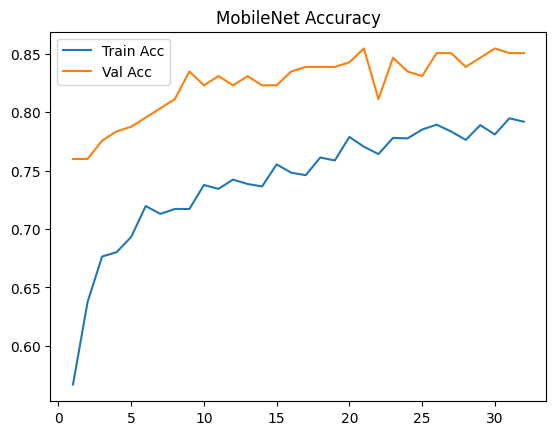

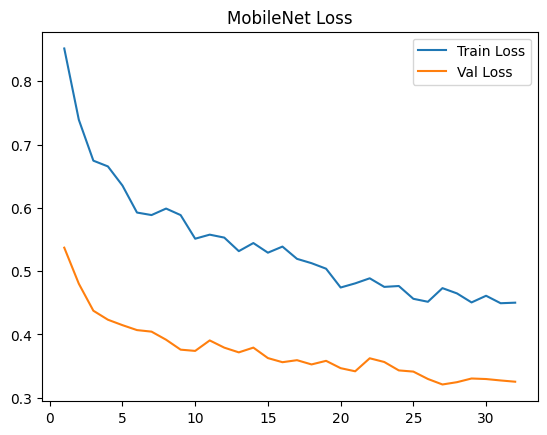

In [8]:
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']

loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

epochs = range(1, len(acc)+1)

plt.figure()
plt.plot(epochs, acc, label='Train Acc')
plt.plot(epochs, val_acc, label='Val Acc')
plt.title('MobileNet Accuracy')
plt.legend()
plt.show()

plt.figure()
plt.plot(epochs, loss, label='Train Loss')
plt.plot(epochs, val_loss, label='Val Loss')
plt.title('MobileNet Loss')
plt.legend()
plt.show()

In [9]:
test_data.reset()
predictions = model.predict(test_data)

y_pred = (predictions > 0.5).astype(int).flatten()
y_true = test_data.classes

labels = {v: k for k, v in test_data.class_indices.items()}

 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step

2026-03-31 18:37:43.069260: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 18:37:43.224601: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 18:37:43.361386: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step


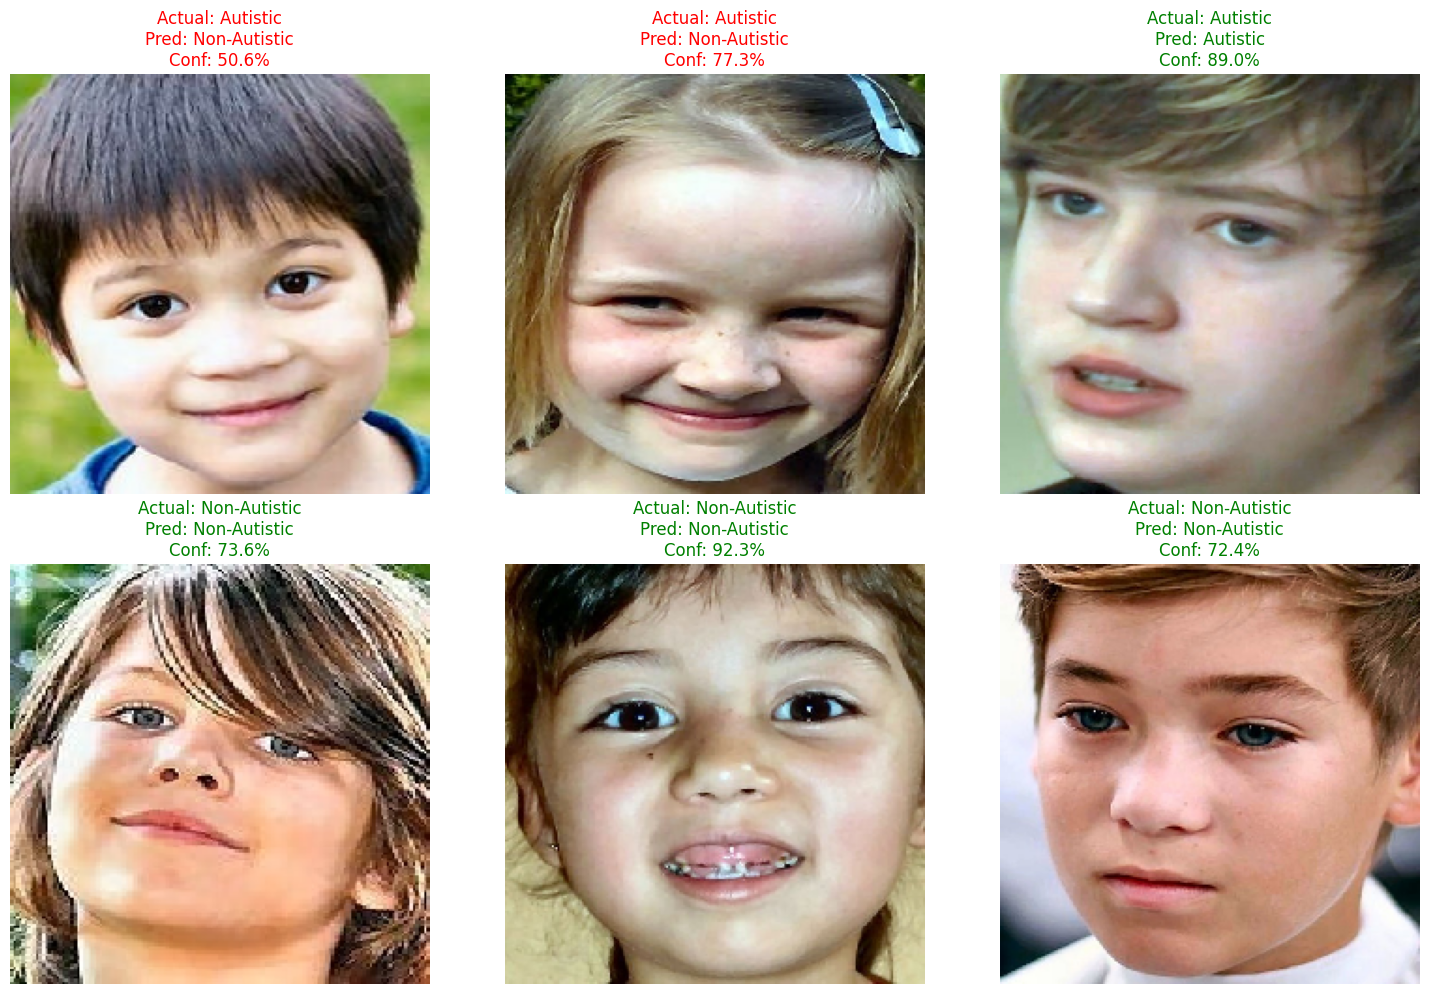

In [10]:
plt.figure(figsize=(15, 10))

for i in range(6):
    idx = np.random.randint(0, len(test_data.filenames))

    img_path = os.path.join(test_dir, test_data.filenames[idx])
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))

    plt.subplot(2, 3, i+1)
    plt.imshow(img)

    actual = labels[y_true[idx]]
    pred = labels[y_pred[idx]]

    # 🔥 Confidence (clean version)
    prob = predictions[idx][0]
    conf = prob if y_pred[idx] == 1 else (1 - prob)

    color = 'green' if actual == pred else 'red'

    plt.title(f"Actual: {actual}\nPred: {pred}\nConf: {conf*100:.1f}%", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

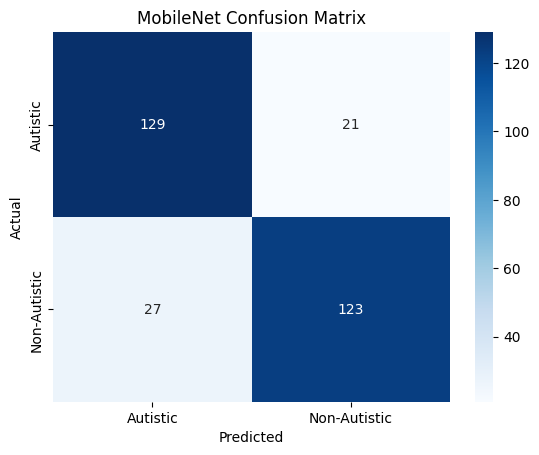

In [11]:
cm = confusion_matrix(y_true, y_pred)

plt.figure()

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=list(labels.values()),
    yticklabels=list(labels.values())
)

plt.title('MobileNet Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [12]:
print(classification_report(
    y_true,
    y_pred,
    target_names=list(labels.values())
))

              precision    recall  f1-score   support

    Autistic       0.83      0.86      0.84       150
Non-Autistic       0.85      0.82      0.84       150

    accuracy                           0.84       300
   macro avg       0.84      0.84      0.84       300
weighted avg       0.84      0.84      0.84       300



In [13]:
model.save('/kaggle/working/mobilenet_final.h5')